In [1]:
# ============================================
# NBA Injury Project
# library：pandas, numpy, matplotlib, seaborn
# ============================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style="whitegrid", font_scale=1.1)

# --------------- 1. read data -----------------
inj_path = '/Users/ritaronaldo/Library/CloudStorage/OneDrive-Emory/COURSE/585/final proj/NBA Player Injury Stats(1951 - 2023).csv'
stats_path = '/Users/ritaronaldo/Library/CloudStorage/OneDrive-Emory/COURSE/585/final proj/NBA Player Stats(1950 - 2022).csv'
box_path = '/Users/ritaronaldo/Library/CloudStorage/OneDrive-Emory/COURSE/585/final proj/NBA Player Box Score Stats(1950 - 2022).csv'

inj = pd.read_csv(inj_path)
stats = pd.read_csv(stats_path)
box = pd.read_csv(box_path)

inj = inj.drop(columns=[col for col in inj.columns if col.startswith("Unnamed")], errors="ignore")
stats = stats.drop(columns=[col for col in stats.columns if col.startswith("Unnamed")], errors="ignore")
box = box.drop(columns=[col for col in box.columns if col.startswith("Unnamed")], errors="ignore")

print("Injury columns:", inj.columns.tolist())
print("Season stats columns:", stats.columns.tolist())
print("Box score columns:", box.columns.tolist())

Injury columns: ['Date', 'Team', 'Acquired', 'Relinquished', 'Notes']
Season stats columns: ['Season', 'Player', 'Pos', 'Age', 'Tm', 'G', 'GS', 'MP', 'FG', 'FGA', 'FG%', '3P', '3PA', '3P%', '2P', '2PA', '2P%', 'eFG%', 'FT', 'FTA', 'FT%', 'ORB', 'DRB', 'TRB', 'AST', 'STL', 'BLK', 'TOV', 'PF', 'PTS']
Box score columns: ['Season', 'Game_ID', 'PLAYER_NAME', 'Team', 'GAME_DATE', 'MATCHUP', 'WL', 'MIN', 'FGM', 'FGA', 'FG_PCT', 'FG3M', 'FG3A', 'FG3_PCT', 'FTM', 'FTA', 'FT_PCT', 'OREB', 'DREB', 'REB', 'AST', 'STL', 'BLK', 'TOV', 'PF', 'PTS', 'PLUS_MINUS', 'VIDEO_AVAILABLE']


In [2]:
# --------------- 2. preprocessing -----------------
# 2.1 date
inj["Date"] = pd.to_datetime(inj["Date"], errors="coerce")
inj["year"] = inj["Date"].dt.year
inj = inj.dropna(subset=["Date"])  # drop date NA

# 2.2 player name formate
inj["player_upper"] = inj["Relinquished"].str.upper().str.strip()
stats["player_upper"] = stats["Player"].str.upper().str.strip()
box["player_upper"] = box["PLAYER_NAME"].str.upper().str.strip()

# 2.3 season year, i.e. "2015-16" -> 2015
def season_to_year(season):
    # season "2015-16"
    try:
        return int(str(season)[:4])
    except:
        return np.nan

stats["season_year"] = stats["Season"].apply(season_to_year)
box["season_year"] = box["Season"].apply(season_to_year)

# only keep year
stats = stats.dropna(subset=["season_year"])
box = box.dropna(subset=["season_year"])
stats["season_year"] = stats["season_year"].astype(int)
box["season_year"] = box["season_year"].astype(int)

In [3]:
# --------------- 3. from Notes extract injuries type -----------------
# keyword 
inj["Notes_clean"] = inj["Notes"].fillna("").str.lower()

injury_dict = {
    "Ankle/Foot": ["ankle", "foot", "toe", "achilles", "heel", "plantar"],
    "Knee/Leg": ["knee", "leg", "calf", "thigh", "hamstring", "quadricep", "groin", "hip"],
    "Back": ["back", "spine", "disc"],
    "Shoulder/Arm": ["shoulder", "arm", "bicep", "tricep", "elbow", "wrist", "hand", "finger", "thumb"],
    "Head/Neck": ["concussion", "head", "neck", "face", "nose", "eye"],
    "Illness": ["illness", "flu", "virus", "covid", "cold", "infection", "fever", "pneumonia"],
    "Torso/Core": ["rib", "chest", "abdomen", "oblique", "core", "stomach"],
}

def classify_injury(note):
    """
    match keywords, return injury
    if no, return None。
    """
    for group, keywords in injury_dict.items():
        for kw in keywords:
            if kw in note:
                return group
    return None

inj["injury_group"] = inj["Notes_clean"].apply(classify_injury)

# only keep records with specific injury type
inj_injury = inj.dropna(subset=["injury_group"]).copy()

print("Total injury rows with classified type:", len(inj_injury))

Total injury rows with classified type: 12038


做直方图的特征列： ['Age', 'G', 'GS', 'MP', 'PTS', 'FGA', 'TRB', 'AST', 'STL', 'BLK', 'TOV', 'PF']


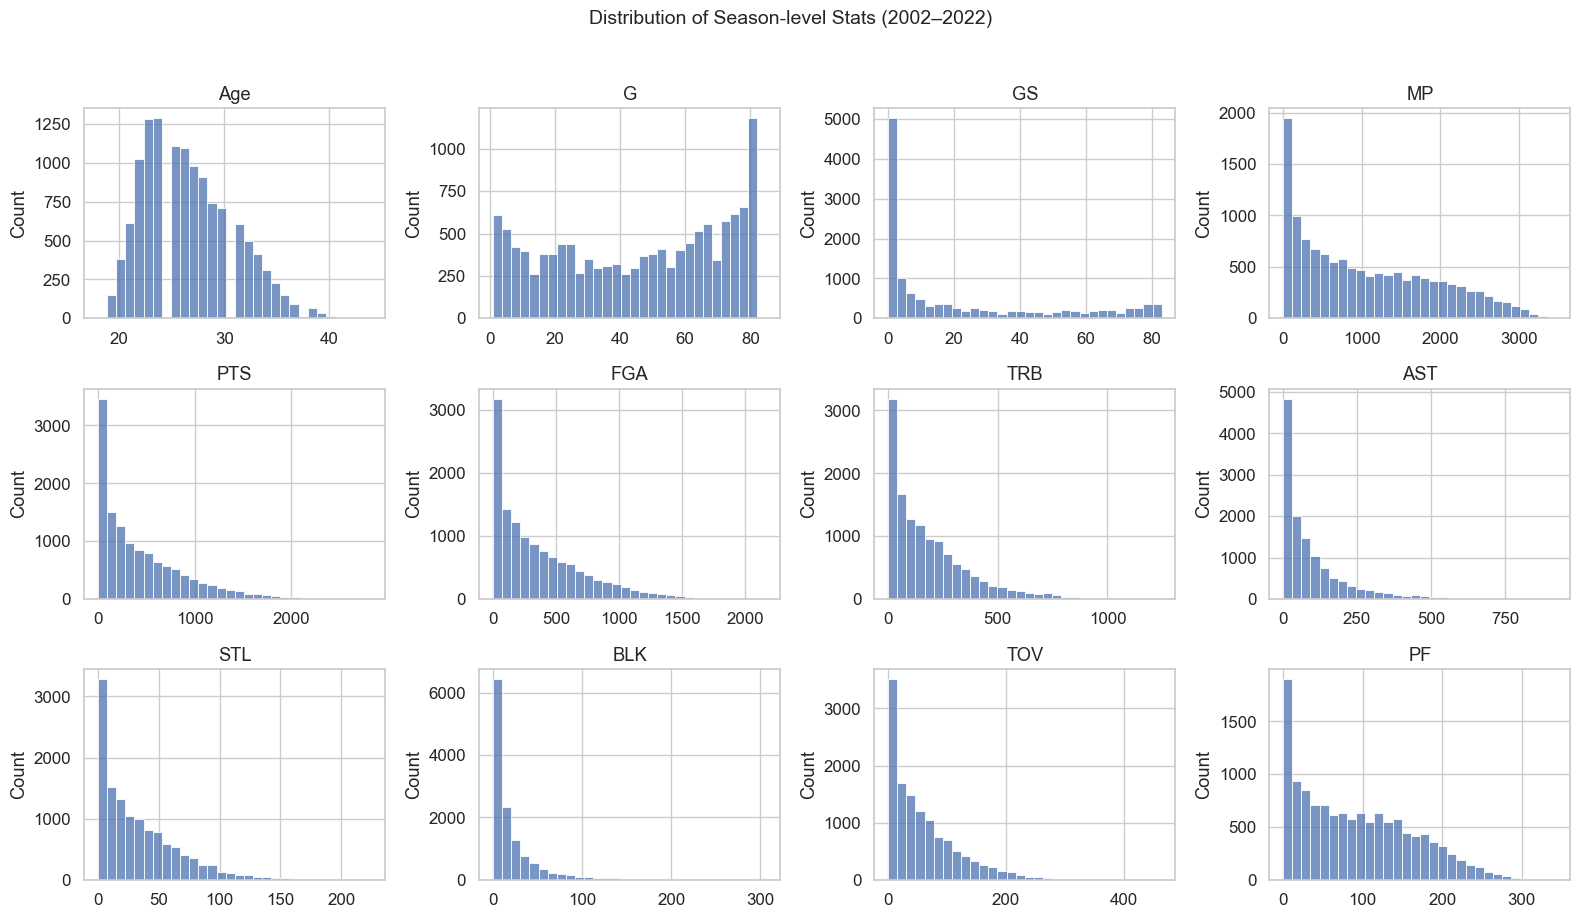

In [4]:
# ======================================================
# EDA 1: 赛季统计数据的分布（直方图）
# ======================================================

# 只看现代数据，避免1950年代那种完全不同的篮球环境
stats_eda = stats[stats["season_year"].between(2002, 2022)].copy()

# 选一批我们后面会用到、也比较有意义的数值变量
eda_cols = [
    "Age", "G", "GS", "MP", 
    "PTS", "FGA", "TRB", "AST", 
    "STL", "BLK", "TOV", "PF"
]

# 确保这些列都存在
eda_cols = [c for c in eda_cols if c in stats_eda.columns]
print("做直方图的特征列：", eda_cols)

n_cols = 4  # 每行放4张图
n_rows = int(np.ceil(len(eda_cols) / n_cols))

plt.figure(figsize=(4 * n_cols, 3 * n_rows))

for i, col in enumerate(eda_cols, 1):
    plt.subplot(n_rows, n_cols, i)
    sns.histplot(stats_eda[col], bins=30, kde=False)
    plt.title(col)
    plt.xlabel("")
    plt.ylabel("Count")

plt.suptitle("Distribution of Season-level Stats (2002–2022)", y=1.02, fontsize=14)
plt.tight_layout()
plt.show()


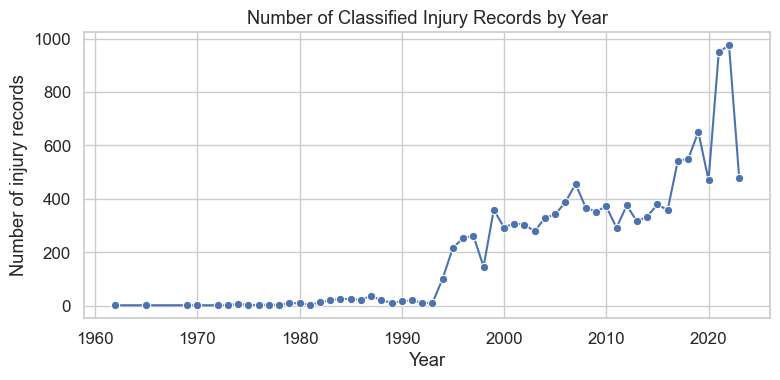

In [5]:
# ======================================================
# EDA 2: 伤病记录按年份的趋势
# 看看有没有明显异常的年份 / 数据质量问题
# ======================================================

inj_year_counts = (
    inj_injury
    .groupby("year")
    .size()
    .reset_index(name="injury_records")
)

plt.figure(figsize=(8, 4))
sns.lineplot(data=inj_year_counts, x="year", y="injury_records", marker="o")
plt.title("Number of Classified Injury Records by Year")
plt.xlabel("Year")
plt.ylabel("Number of injury records")
plt.tight_layout()
plt.show()


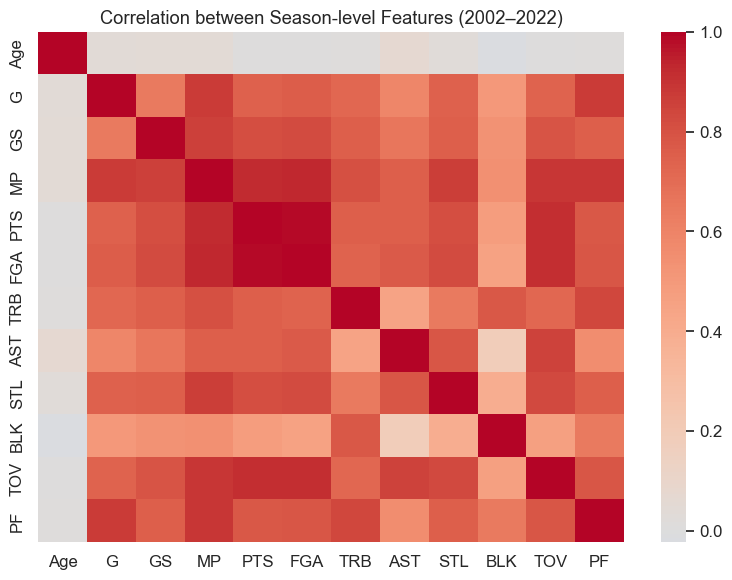

In [6]:
# ======================================================
# EDA 3（可选）：变量之间的相关性热力图
# ======================================================

corr_df = stats_eda[eda_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr_df, annot=False, cmap="coolwarm", center=0)
plt.title("Correlation between Season-level Features (2002–2022)")
plt.tight_layout()
plt.show()


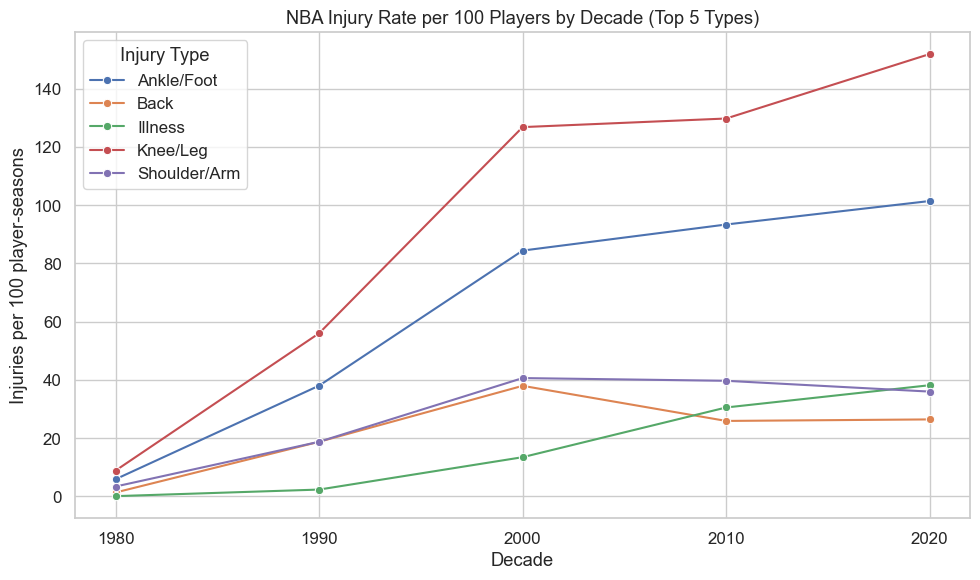

In [15]:
# ======================================================
# Q1: 不同年代的主流伤病类型（按球员人数标准化）
# ======================================================

# decade: 用十年为单位，比如 1980s, 1990s ...
inj_injury = inj_injury.dropna(subset=["year"])
inj_injury["decade"] = (inj_injury["year"] // 10) * 10

# 为了记录比较完整，只看 1980 年之后
inj_injury_dec = inj_injury[inj_injury["year"] >= 1980].copy()

# 1) 每个 decade + injury_group 的伤病条数
decade_group_counts = (
    inj_injury_dec
    .groupby(["decade", "injury_group"])
    .size()
    .reset_index(name="inj_count")
)

# 2) 每个 decade 有多少独立球员（用 season stats 近似）
stats_dec = stats.copy()
stats_dec["decade"] = (stats_dec["season_year"] // 10) * 10
stats_dec = stats_dec[stats_dec["decade"] >= 1980]

players_per_decade = (
    stats_dec
    .groupby("decade")["player_upper"]
    .nunique()
    .reset_index(name="n_players")
)

# 3) 合并：算每 100 名球员的伤病数
decade_group_counts = decade_group_counts.merge(players_per_decade, on="decade", how="left")
decade_group_counts["inj_per_100_players"] = decade_group_counts["inj_count"] / decade_group_counts["n_players"] * 100

# 只画出现次数最多的前 5 种伤病
top_groups = (
    inj_injury_dec["injury_group"]
    .value_counts()
    .head(5)
    .index
)
decade_group_top = decade_group_counts[decade_group_counts["injury_group"].isin(top_groups)]

plt.figure(figsize=(10, 6))
sns.lineplot(
    data=decade_group_top,
    x="decade",
    y="inj_per_100_players",
    hue="injury_group",
    marker="o"
)
plt.title("NBA Injury Rate per 100 Players by Decade (Top 5 Types)")
plt.xlabel("Decade")
plt.ylabel("Injuries per 100 player-seasons")
plt.xticks(sorted(decade_group_top["decade"].unique()))
plt.legend(title="Injury Type")
plt.tight_layout()
plt.show()


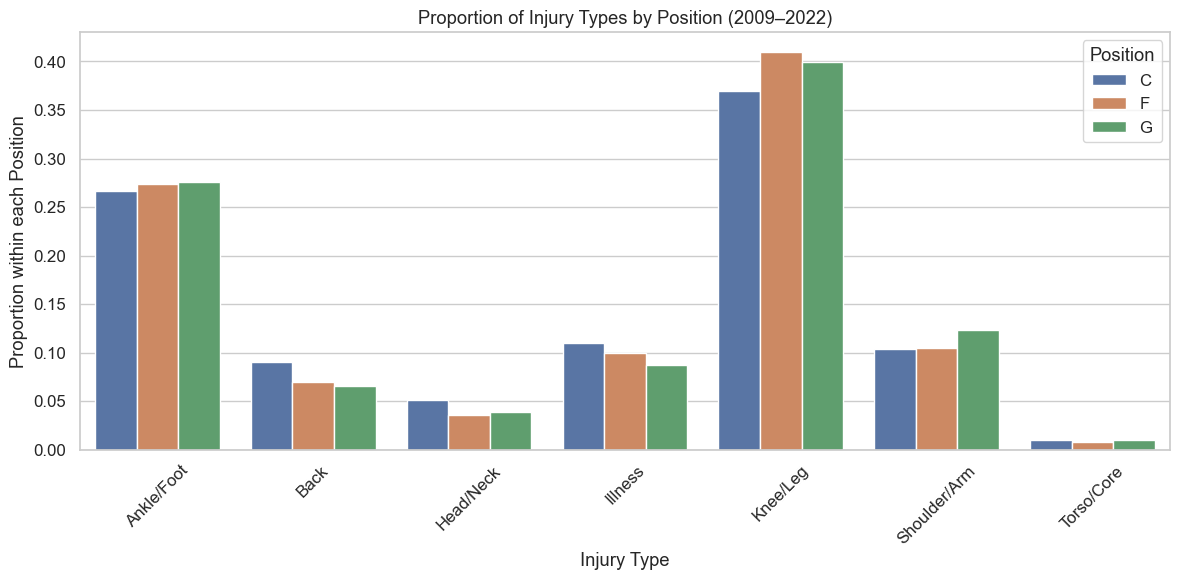

In [19]:
# ======================================================
# Q2 Alternative: 分组柱状图（更容易看）
# ======================================================

inj_recent = inj_injury[(inj_injury["year"] >= 2009) & (inj_injury["year"] <= 2022)].copy()
stats_recent = stats[(stats["season_year"] >= 2009) & (stats["season_year"] <= 2022)].copy()

inj_recent["season_year"] = inj_recent["year"]

merged_pos = pd.merge(
    inj_recent[["Date", "player_upper", "season_year", "injury_group"]],
    stats_recent[["player_upper", "season_year", "Pos"]],
    on=["player_upper", "season_year"],
    how="left"
)
merged_pos = merged_pos.dropna(subset=["Pos"]).copy()

# 简化位置：G/F/C
def simplify_pos(pos):
    if "G" in pos:
        return "G"
    if "C" in pos:
        return "C"
    if "F" in pos:
        return "F"
    return pos

merged_pos["Pos_simple"] = merged_pos["Pos"].apply(simplify_pos)

# 按位置内部归一化（各位置百分比）
pos_injury_crosstab = pd.crosstab(merged_pos["Pos_simple"], merged_pos["injury_group"])
pos_injury_prop = pos_injury_crosstab.div(pos_injury_crosstab.sum(axis=1), axis=0)

# 为画分组柱状图，把表格转换成长格式
plot_df = pos_injury_prop.reset_index().melt(id_vars="Pos_simple", var_name="InjuryType", value_name="Prop")

plt.figure(figsize=(12,6))
sns.barplot(
    data=plot_df,
    x="InjuryType",
    y="Prop",
    hue="Pos_simple"
)
plt.title("Proportion of Injury Types by Position (2009–2022)")
plt.xlabel("Injury Type")
plt.ylabel("Proportion within each Position")
plt.xticks(rotation=45)
plt.legend(title="Position")
plt.tight_layout()
plt.show()



示例几行 team-season 伤病：
    Team  year  inj_count
0  76ers  2015          4
1  76ers  2016          9
2  76ers  2017         16
3  76ers  2018         14
4  76ers  2019         36
按平均每赛季伤病排序（前20）：
         Team  inj_count
5     Celtics     32.250
28   Warriors     26.000
16  Mavericks     24.875
22    Raptors     24.250
7   Grizzlies     24.250
8       Hawks     24.000
2       Bucks     23.875
13     Knicks     22.125
19     Pacers     21.875
24      Spurs     21.750
11       Jazz     21.625
0       76ers     20.875
14     Lakers     20.750
9        Heat     20.375
18    Nuggets     20.375
21    Pistons     20.000
4   Cavaliers     19.875
17       Nets     19.500
3       Bulls     19.000
23    Rockets     18.750


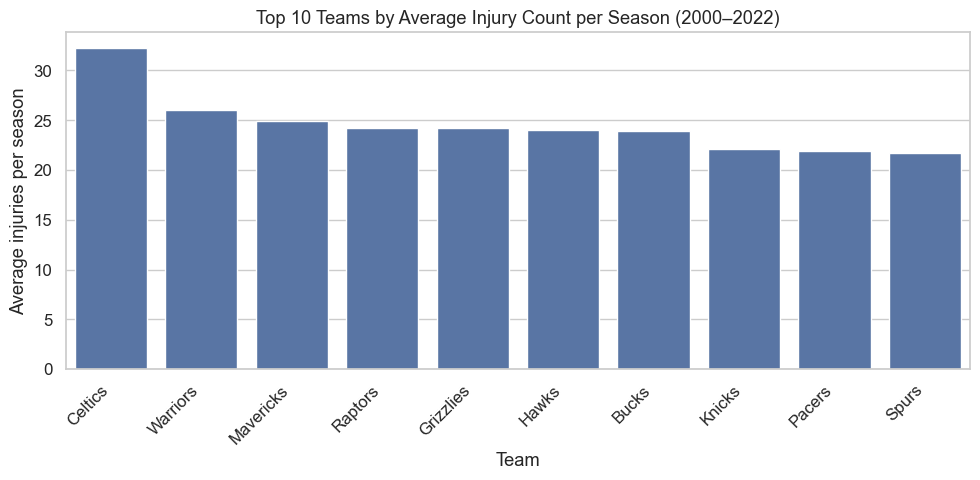

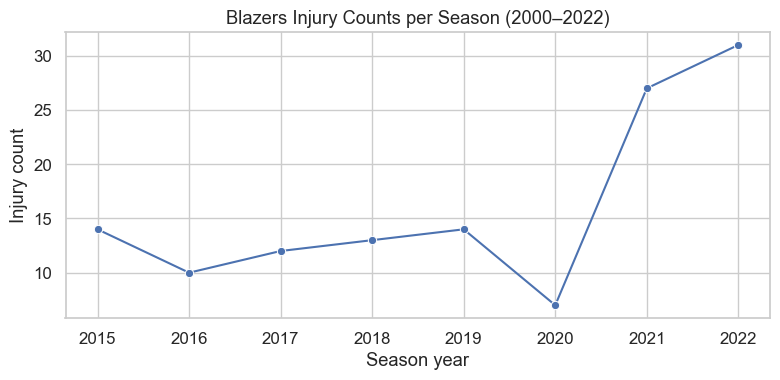

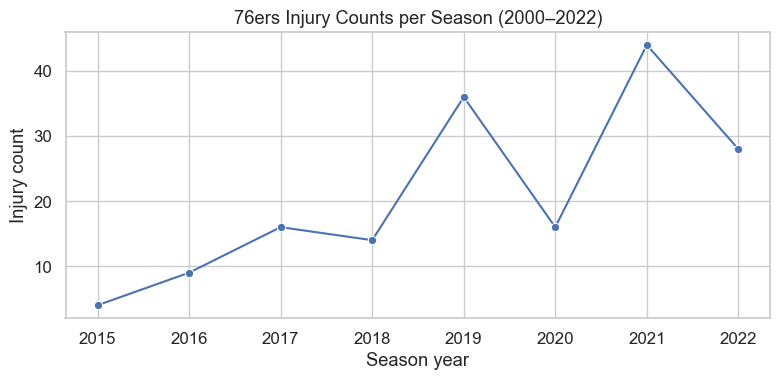

In [31]:
# =========================================
# A. Team-level injury counts (2000–2022)
# =========================================

# 只用已经分类过的 injury 表 inj_injury（有 year, injury_group, Team）
inj_team = inj_injury.copy()
inj_team = inj_team[inj_team["year"].between(2015, 2022)]

# 1) 每个 team-season 的伤病条数
team_season_inj = (
    inj_team
    .groupby(["Team", "year"])
    .size()
    .reset_index(name="inj_count")
)

print("示例几行 team-season 伤病：")
print(team_season_inj.head())

# 2) 每个球队 2000–2022 平均每赛季伤病条数
team_avg = (
    team_season_inj
    .groupby("Team")["inj_count"]
    .mean()
    .reset_index()
    .sort_values("inj_count", ascending=False)
)

print("按平均每赛季伤病排序（前20）：")
print(team_avg.head(20))

# 3) 画前10名
top10 = team_avg.head(10)

plt.figure(figsize=(10, 5))
sns.barplot(data=top10, x="Team", y="inj_count")
plt.title("Top 10 Teams by Average Injury Count per Season (2000–2022)")
plt.xlabel("Team")
plt.ylabel("Average injuries per season")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# 4) 单独看 Blazers 的时间趋势（如果你想看）
blazers = team_season_inj[team_season_inj["Team"] == "Blazers"].sort_values("year")

plt.figure(figsize=(8, 4))
sns.lineplot(data=blazers, x="year", y="inj_count", marker="o")
plt.title("Blazers Injury Counts per Season (2000–2022)")
plt.xlabel("Season year")
plt.ylabel("Injury count")
plt.tight_layout()
plt.show()

# 4) 单独看 76ers 的时间趋势（如果你想看）
blazers = team_season_inj[team_season_inj["Team"] == "76ers"].sort_values("year")

plt.figure(figsize=(8, 4))
sns.lineplot(data=blazers, x="year", y="inj_count", marker="o")
plt.title("76ers Injury Counts per Season (2000–2022)")
plt.xlabel("Season year")
plt.ylabel("Injury count")
plt.tight_layout()
plt.show()


样本总行数： 12711
受伤 vs 未受伤标签分布：
y_injured
1.0    6978
0.0    5733
Name: count, dtype: int64
实际可用的特征： ['Age', 'MP', 'G', 'GS', 'PTS', 'FGA', 'TRB', 'STL', 'BLK', 'PF', 'TOV']
用于建模的样本数： 12711
=== Classification report ===
              precision    recall  f1-score   support

         0.0      0.519     0.138     0.218      1720
         1.0      0.558     0.895     0.688      2094

    accuracy                          0.553      3814
   macro avg      0.538     0.516     0.453      3814
weighted avg      0.540     0.553     0.476      3814

AUC: 0.5362580795628706


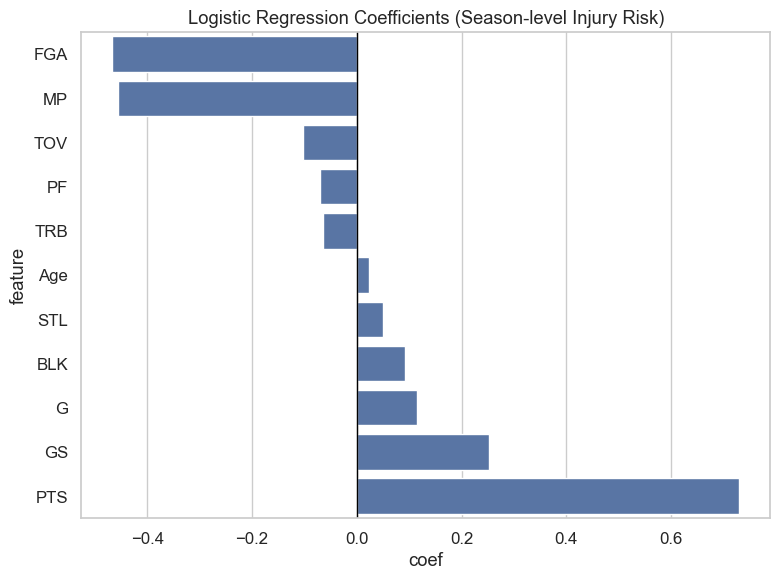

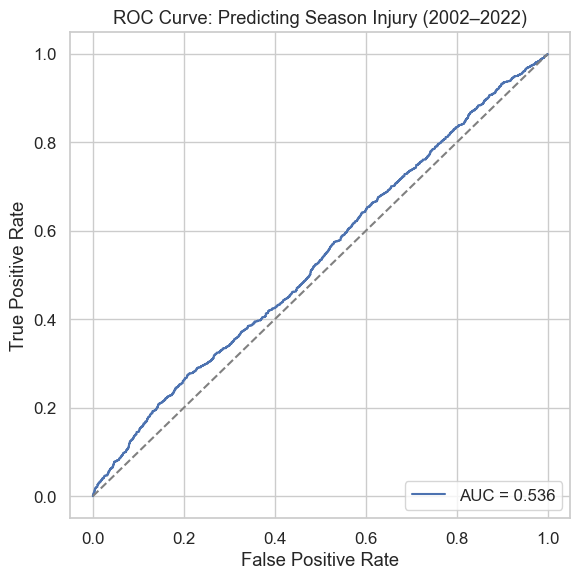

In [32]:
# ============================================
# NBA Injury – Season-level Logistic Regression
# y = 是否在该赛季有至少一次受伤记录
# X = Age, MP, G, GS, PTS, FGA, TRB, STL, BLK, PF, TOV
# 时间范围：2002–2022 赛季
# ============================================


from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, roc_auc_score, roc_curve



# ---------- 3. 只取 2002–2022 的数据 ----------
inj_mod = inj[inj["year"].between(2002, 2022)].copy()
stats_mod = stats[stats["season_year"].between(2002, 2022)].copy()

# ---------- 4. 构造赛季级别受伤标签 y ----------

# 对于每个 (球员, 年份) 统计有没有受伤记录
inj_season = (
    inj_mod.groupby(["player_upper", "year"])
    .size()
    .reset_index(name="inj_count")
    .rename(columns={"year": "season_year"})
)
inj_season["y_injured"] = 1  # 只要有记录就是 1

# 把受伤信息 merge 到赛季 stats 数据上
merged = stats_mod.merge(
    inj_season[["player_upper", "season_year", "y_injured"]],
    on=["player_upper", "season_year"],
    how="left"
)
merged["y_injured"] = merged["y_injured"].fillna(0)  # 没有记录的记为 0

print("样本总行数：", len(merged))
print("受伤 vs 未受伤标签分布：")
print(merged["y_injured"].value_counts())

# ---------- 5. 选择特征 X ----------

# 这 11 个是我们挑的、和伤病最相关的一组变量
Xvars = ["Age", "MP", "G", "GS", "PTS", "FGA", "TRB", "STL", "BLK", "PF", "TOV"]

# 有些数据集可能缺少个别列，这里做一下保险
Xvars_present = [c for c in Xvars if c in merged.columns]
print("实际可用的特征：", Xvars_present)

# 去掉这些列中有缺失值的行
model_df = merged.dropna(subset=Xvars_present + ["y_injured"])

X = model_df[Xvars_present].values
y = model_df["y_injured"].values

print("用于建模的样本数：", len(model_df))

# ---------- 6. 划分训练集 / 测试集 ----------
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

# ---------- 7. 标准化 + 逻辑回归 ----------
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

logreg = LogisticRegression(max_iter=2000)
logreg.fit(X_train_s, y_train)

y_pred = logreg.predict(X_test_s)
y_proba = logreg.predict_proba(X_test_s)[:, 1]

# ---------- 8. 输出 summary ----------
print("=== Classification report ===")
print(classification_report(y_test, y_pred, digits=3))

auc = roc_auc_score(y_test, y_proba)
print("AUC:", auc)

# ---------- 9. 画系数条形图 ----------
coef_df = pd.DataFrame({
    "feature": Xvars_present,
    "coef": logreg.coef_[0]
}).sort_values("coef", ascending=True)

plt.figure(figsize=(8, 6))
sns.barplot(data=coef_df, x="coef", y="feature")
plt.title("Logistic Regression Coefficients (Season-level Injury Risk)")
plt.axvline(0, color="black", linewidth=1)
plt.tight_layout()
plt.show()

# ---------- 10. 画 ROC 曲线 ----------
fpr, tpr, _ = roc_curve(y_test, y_proba)

plt.figure(figsize=(6, 6))
plt.plot(fpr, tpr, label=f"AUC = {auc:.3f}")
plt.plot([0, 1], [0, 1], "--", color="gray")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve: Predicting Season Injury (2002–2022)")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()
